In [3]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

sns.set_theme(style="whitegrid")

In [4]:
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Seaborn:", sns.__version__)

NumPy: 2.5.3
Pandas: 3.0.6
Seaborn: 0.13.2


In [6]:
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid")

print("DataCenterIQ analysis environment ready.")

DataCenterIQ analysis environment ready.


In [8]:
possible_paths = [
    Path("../data/amd_datacenter_gpus.csv"),
    Path("data/amd_datacenter_gpus.csv"),
    Path(r"E:/DataCenterIQ/data/amd_datacenter_gpus.csv"),
]

DATA_PATH = next((p for p in possible_paths if p.exists()), None)

if DATA_PATH is None:
    print("Dataset not found.")
    print("Place the CSV at: E:/DataCenterIQ/data/amd_datacenter_gpus.csv")
else:
    df = pd.read_csv(DATA_PATH)
    print(f"Loaded: {DATA_PATH.resolve()}")
    print(f"Rows: {df.shape[0]:,}")
    print(f"Columns: {df.shape[1]:,}")
    display(df.head())

Loaded: E:\DataCenterIQ\data\amd_datacenter_gpus.csv
Rows: 8
Columns: 29


,gpu_name,series,architecture,codename,form_factor,launch_year,process_node_nm,die_size_mm2,transistor_count_millions,compute_units,matrix_cores,stream_processors,base_clock_mhz,boost_clock_mhz,memory_size_gb,memory_type,memory_bus_bit,memory_bandwidth_gbs,fp64_tflops,fp32_tflops,fp16_tflops,fp8_tflops,tdp_watts,launch_price_usd,transistor_density_m_per_mm2,fp32_gflops_per_dollar,fp32_gflops_per_watt,fp16_tflops_per_watt,fp8_tflops_per_watt
0,AMD FirePro S9150,FirePro Server,GCN 2.0,Hawaii,PCIe Full-Height,2014,28,438.0,6200.0,44,0,2816,900,900,16.0,GDDR5,512,320.0,2.53,5.07,5.07,5.07,235.0,3299.0,14.16,1.54,21.57,0.022,0.022
1,AMD Radeon Instinct MI25,Instinct MI,GCN 5.0 (Vega),Vega 10,PCIe Passive,2017,14,486.0,12500.0,64,0,4096,1400,1500,16.0,HBM2,2048,484.0,0.77,12.29,24.58,24.58,300.0,4500.0,25.72,2.73,40.97,0.082,0.082
2,AMD Instinct MI50 (32GB),Instinct MI,GCN 5.0 (Vega 20),Vega 20,PCIe Full-Height,2018,7,331.0,13200.0,60,0,3840,1450,1725,32.0,HBM2,4096,1024.0,6.62,13.25,26.50,26.50,300.0,5900.0,39.88,2.25,44.17,0.088,0.088
3,AMD Instinct MI100 (CDNA 1),Instinct MI,CDNA 1.0,Arcturus,PCIe Full-Height,2020,7,750.0,25600.0,120,480,7680,1000,1502,32.0,HBM2,4096,1228.8,11.54,23.07,184.60,184.60,300.0,7400.0,34.13,3.12,76.90,0.615,0.615
4,AMD Instinct MI250X (OAM 560W),Instinct MI,CDNA 2.0 (Dual-GCD),Aldebaran,OAM Module,2021,6,1540.0,58200.0,220,880,14080,1000,1700,128.0,HBM2e,8192,3276.8,47.90,47.90,383.00,383.00,560.0,14500.0,37.79,3.30,85.54,0.684,0.684


In [9]:
if "df" in globals():
    print("Columns:")
    print(df.columns.tolist())

    print("\nData types:")
    display(df.dtypes.to_frame("dtype"))

    print("\nMissing values:")
    missing = df.isna().sum().to_frame("missing_count")
    missing["missing_pct"] = (missing["missing_count"] / len(df) * 100).round(2)
    display(missing.sort_values("missing_count", ascending=False))

    print("\nDuplicate rows:", df.duplicated().sum())
else:
    print("Load the dataset first.")

Columns:
['gpu_name', 'series', 'architecture', 'codename', 'form_factor', 'launch_year', 'process_node_nm', 'die_size_mm2', 'transistor_count_millions', 'compute_units', 'matrix_cores', 'stream_processors', 'base_clock_mhz', 'boost_clock_mhz', 'memory_size_gb', 'memory_type', 'memory_bus_bit', 'memory_bandwidth_gbs', 'fp64_tflops', 'fp32_tflops', 'fp16_tflops', 'fp8_tflops', 'tdp_watts', 'launch_price_usd', 'transistor_density_m_per_mm2', 'fp32_gflops_per_dollar', 'fp32_gflops_per_watt', 'fp16_tflops_per_watt', 'fp8_tflops_per_watt']

Data types:


,dtype
gpu_name,str
series,str
architecture,str
codename,str
form_factor,str
launch_year,int64
process_node_nm,int64
die_size_mm2,float64
transistor_count_millions,float64
compute_units,int64



Missing values:


,missing_count,missing_pct
gpu_name,0,0.0
series,0,0.0
architecture,0,0.0
codename,0,0.0
form_factor,0,0.0
launch_year,0,0.0
process_node_nm,0,0.0
die_size_mm2,0,0.0
transistor_count_millions,0,0.0
compute_units,0,0.0



Duplicate rows: 0


In [10]:
if "df" in globals():
    original_columns = df.columns.tolist()

    df.columns = [
        re.sub(r"[^a-zA-Z0-9]+", "_", str(c).strip().lower()).strip("_")
        for c in df.columns
    ]

    print("Column mapping:")
    for old, new in zip(original_columns, df.columns):
        print(f"{old} -> {new}")

Column mapping:
gpu_name -> gpu_name
series -> series
architecture -> architecture
codename -> codename
form_factor -> form_factor
launch_year -> launch_year
process_node_nm -> process_node_nm
die_size_mm2 -> die_size_mm2
transistor_count_millions -> transistor_count_millions
compute_units -> compute_units
matrix_cores -> matrix_cores
stream_processors -> stream_processors
base_clock_mhz -> base_clock_mhz
boost_clock_mhz -> boost_clock_mhz
memory_size_gb -> memory_size_gb
memory_type -> memory_type
memory_bus_bit -> memory_bus_bit
memory_bandwidth_gbs -> memory_bandwidth_gbs
fp64_tflops -> fp64_tflops
fp32_tflops -> fp32_tflops
fp16_tflops -> fp16_tflops
fp8_tflops -> fp8_tflops
tdp_watts -> tdp_watts
launch_price_usd -> launch_price_usd
transistor_density_m_per_mm2 -> transistor_density_m_per_mm2
fp32_gflops_per_dollar -> fp32_gflops_per_dollar
fp32_gflops_per_watt -> fp32_gflops_per_watt
fp16_tflops_per_watt -> fp16_tflops_per_watt
fp8_tflops_per_watt -> fp8_tflops_per_watt


In [11]:
def find_column(frame, candidates):
    exact = {str(c).lower(): c for c in frame.columns}

    for candidate in candidates:
        if candidate.lower() in exact:
            return exact[candidate.lower()]

    for col in frame.columns:
        name = str(col).lower()
        if any(candidate.lower() in name for candidate in candidates):
            return col

    return None


COLUMN_MAP = {
    "gpu_name": find_column(df, ["gpu_name", "name", "product_name", "model", "gpu"]),
    "series": find_column(df, ["series", "product_series", "family"]),
    "architecture": find_column(df, ["architecture", "arch"]),
    "launch_year": find_column(df, ["launch_year", "release_year", "year"]),
    "process_node_nm": find_column(df, ["process_node_nm", "process_nm", "node_nm", "process_node"]),
    "memory_gb": find_column(df, ["memory_gb", "memory", "vram_gb", "hbm_gb"]),
    "memory_bandwidth_gbps": find_column(df, ["memory_bandwidth_gbps", "memory_bandwidth", "bandwidth_gbps"]),
    "tdp_w": find_column(df, ["tdp_w", "tdp", "power_w", "power"]),
    "compute_performance": find_column(df, ["compute_performance", "performance", "fp32_tflops", "tflops"]),
}

display(pd.DataFrame({
    "analysis_field": list(COLUMN_MAP.keys()),
    "detected_column": list(COLUMN_MAP.values())
}))

,analysis_field,detected_column
0,gpu_name,gpu_name
1,series,series
2,architecture,architecture
3,launch_year,launch_year
4,process_node_nm,process_node_nm
5,memory_gb,memory_size_gb
6,memory_bandwidth_gbps,memory_bandwidth_gbs
7,tdp_w,tdp_watts
8,compute_performance,fp32_tflops


In [12]:
def numeric_series(frame, column):
    if column is None or column not in frame.columns:
        return pd.Series(index=frame.index, dtype="float64")

    return pd.to_numeric(
        frame[column].astype(str)
        .str.replace(",", "", regex=False)
        .str.extract(r"([-+]?\d*\.?\d+)")[0],
        errors="coerce"
    )


for key, source_col in COLUMN_MAP.items():
    if key in {
        "launch_year",
        "process_node_nm",
        "memory_gb",
        "memory_bandwidth_gbps",
        "tdp_w",
        "compute_performance",
    }:
        df[key] = numeric_series(df, source_col)

numeric_cols = [
    c for c in [
        "launch_year",
        "process_node_nm",
        "memory_gb",
        "memory_bandwidth_gbps",
        "tdp_w",
        "compute_performance",
    ]
    if c in df.columns and df[c].notna().any()
]

if numeric_cols:
    display(df[numeric_cols].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
launch_year,8.0,2020.00,3.46,2014.00,2017.75,2020.50,2023.00,2024.0
process_node_nm,8.0,9.62,8.00,5.00,5.00,6.50,8.75,28.0
memory_gb,8.0,100.00,90.81,16.00,28.00,80.00,144.00,256.0
memory_bandwidth_gbps,8.0,2866.70,2392.51,320.00,889.00,2252.80,5300.00,6000.0
tdp_w,8.0,499.38,269.61,235.00,300.00,425.00,607.50,1000.0
compute_performance,8.0,68.87,69.35,5.07,13.01,35.48,132.80,163.4


In [13]:
print(f"Total GPU records: {len(df):,}")

if COLUMN_MAP["gpu_name"]:
    print(f"Unique GPU models: {df[COLUMN_MAP['gpu_name']].nunique():,}")

if COLUMN_MAP["series"]:
    print("\nGPU series:")
    display(df[COLUMN_MAP["series"]].value_counts().to_frame("gpu_count"))

if COLUMN_MAP["architecture"]:
    print("\nArchitectures:")
    display(df[COLUMN_MAP["architecture"]].value_counts().to_frame("gpu_count"))

if df["launch_year"].notna().any():
    print(f"\nLaunch years: {int(df['launch_year'].min())} → {int(df['launch_year'].max())}")

Total GPU records: 8
Unique GPU models: 8

GPU series:


,gpu_count
series,
Instinct MI,7
FirePro Server,1



Architectures:


,gpu_count
architecture,
GCN 2.0,1
GCN 5.0 (Vega),1
GCN 5.0 (Vega 20),1
CDNA 1.0,1
CDNA 2.0 (Dual-GCD),1
CDNA 3.0 + Zen 4,1
CDNA 3.0,1
CDNA 3.0 Refresh,1



Launch years: 2014 → 2024


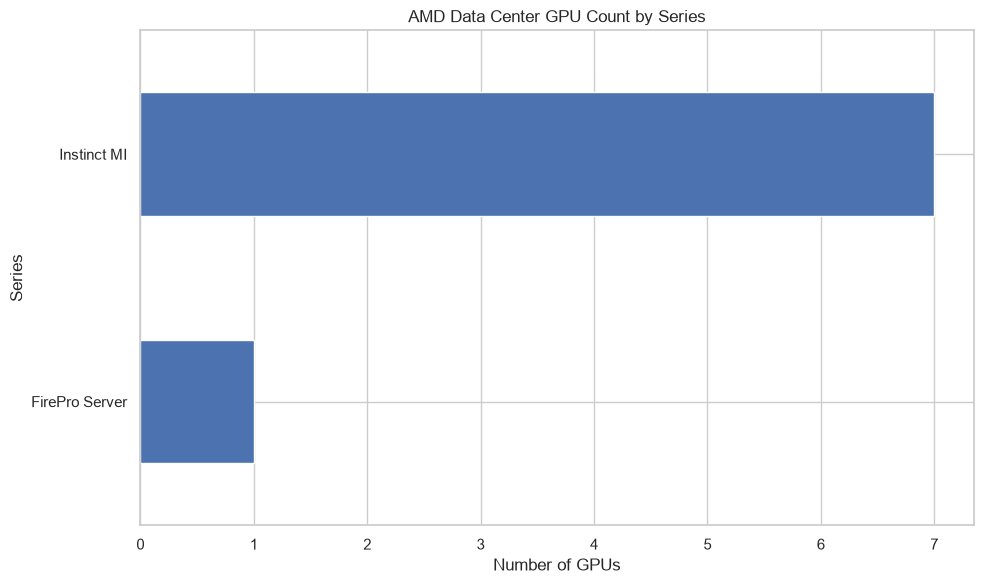

In [14]:
if COLUMN_MAP["series"]:
    counts = df[COLUMN_MAP["series"]].value_counts().sort_values()

    plt.figure(figsize=(10, 6))
    counts.plot(kind="barh")
    plt.title("AMD Data Center GPU Count by Series")
    plt.xlabel("Number of GPUs")
    plt.ylabel("Series")
    plt.tight_layout()
    plt.show()
else:
    print("Series column not detected.")

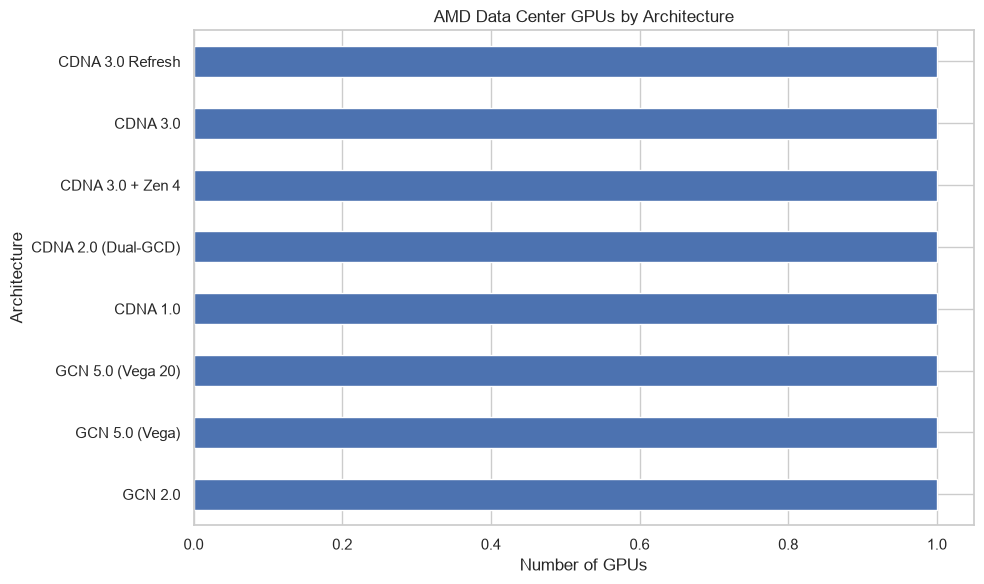

In [15]:
if COLUMN_MAP["architecture"]:
    counts = df[COLUMN_MAP["architecture"]].value_counts().sort_values()

    plt.figure(figsize=(10, 6))
    counts.plot(kind="barh")
    plt.title("AMD Data Center GPUs by Architecture")
    plt.xlabel("Number of GPUs")
    plt.ylabel("Architecture")
    plt.tight_layout()
    plt.show()
else:
    print("Architecture column not detected.")

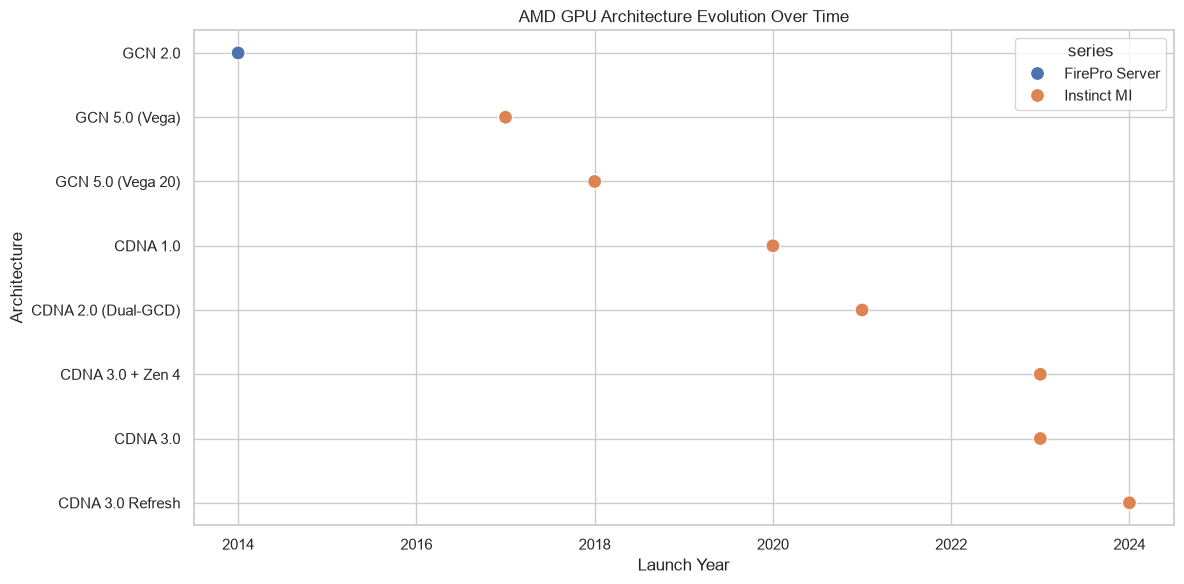

In [16]:
if COLUMN_MAP["architecture"] and df["launch_year"].notna().any():
    plot_df = df.dropna(subset=["launch_year"]).copy()

    plt.figure(figsize=(12, 6))
    sns.scatterplot(
        data=plot_df,
        x="launch_year",
        y=COLUMN_MAP["architecture"],
        hue=COLUMN_MAP["series"] if COLUMN_MAP["series"] else None,
        s=100
    )
    plt.title("AMD GPU Architecture Evolution Over Time")
    plt.xlabel("Launch Year")
    plt.ylabel("Architecture")
    plt.tight_layout()
    plt.show()
else:
    print("Architecture timeline requires architecture and launch year.")

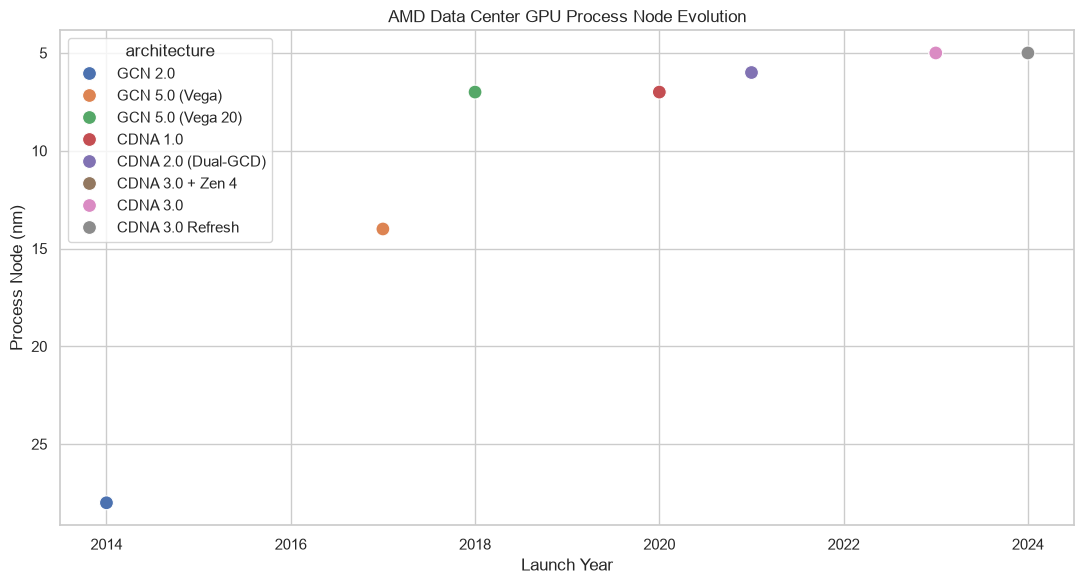

In [17]:
if df["process_node_nm"].notna().any() and df["launch_year"].notna().any():
    plot_df = df.dropna(subset=["launch_year", "process_node_nm"]).sort_values("launch_year")

    plt.figure(figsize=(11, 6))
    sns.scatterplot(
        data=plot_df,
        x="launch_year",
        y="process_node_nm",
        hue=COLUMN_MAP["architecture"] if COLUMN_MAP["architecture"] else None,
        s=100
    )
    plt.title("AMD Data Center GPU Process Node Evolution")
    plt.xlabel("Launch Year")
    plt.ylabel("Process Node (nm)")
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()
else:
    print("Process-node analysis requires launch_year and process_node_nm.")

,gpu_name,series,architecture,memory_gb
7,AMD Instinct MI325X (256GB HBM3e),Instinct MI,CDNA 3.0 Refresh,256.0
6,AMD Instinct MI300X (192GB HBM3),Instinct MI,CDNA 3.0,192.0
4,AMD Instinct MI250X (OAM 560W),Instinct MI,CDNA 2.0 (Dual-GCD),128.0
5,AMD Instinct MI300A (APU),Instinct MI,CDNA 3.0 + Zen 4,128.0
2,AMD Instinct MI50 (32GB),Instinct MI,GCN 5.0 (Vega 20),32.0
3,AMD Instinct MI100 (CDNA 1),Instinct MI,CDNA 1.0,32.0
0,AMD FirePro S9150,FirePro Server,GCN 2.0,16.0
1,AMD Radeon Instinct MI25,Instinct MI,GCN 5.0 (Vega),16.0


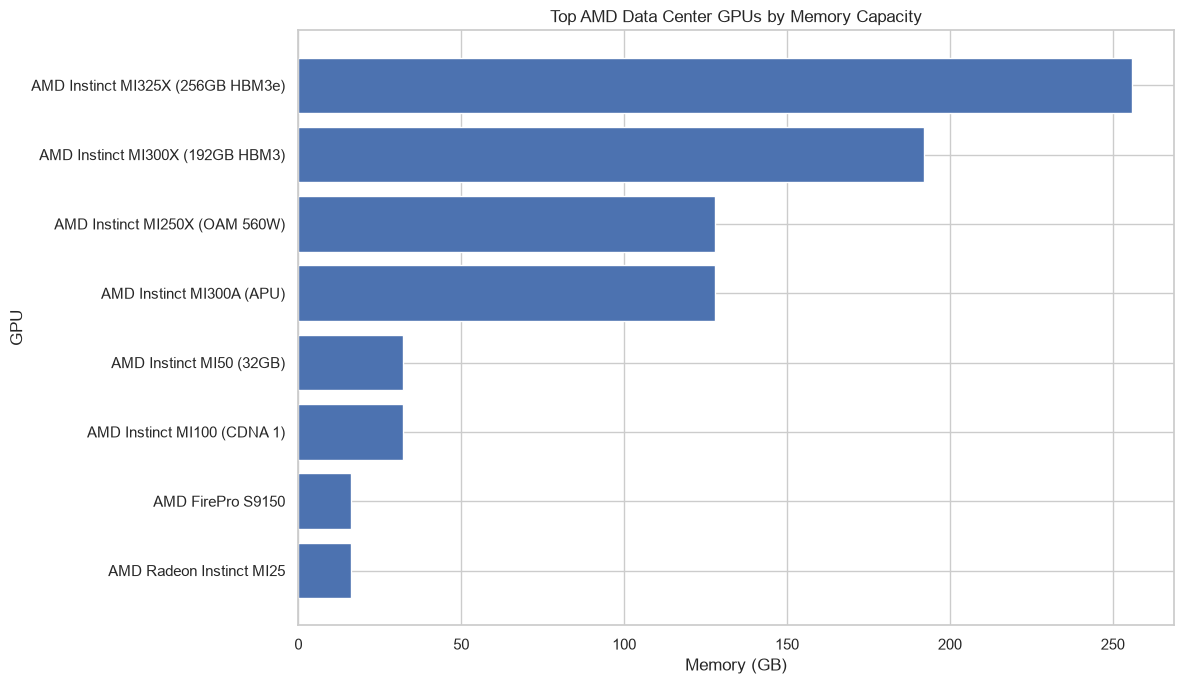

In [18]:
if df["memory_gb"].notna().any():
    plot_df = df.dropna(subset=["memory_gb"]).sort_values("memory_gb", ascending=False)

    cols = [c for c in [
        COLUMN_MAP["gpu_name"],
        COLUMN_MAP["series"],
        COLUMN_MAP["architecture"],
        "memory_gb"
    ] if c]

    display(plot_df[cols].head(20))

    top = plot_df.head(20)

    labels = (
        top[COLUMN_MAP["gpu_name"]].astype(str)
        if COLUMN_MAP["gpu_name"]
        else top.index.astype(str)
    )

    plt.figure(figsize=(12, 7))
    plt.barh(labels[::-1], top["memory_gb"].values[::-1])
    plt.title("Top AMD Data Center GPUs by Memory Capacity")
    plt.xlabel("Memory (GB)")
    plt.ylabel("GPU")
    plt.tight_layout()
    plt.show()
else:
    print("Memory capacity column not detected.")

,gpu_name,architecture,memory_gb,memory_bandwidth_gbps
7,AMD Instinct MI325X (256GB HBM3e),CDNA 3.0 Refresh,256.0,6000.0
5,AMD Instinct MI300A (APU),CDNA 3.0 + Zen 4,128.0,5300.0
6,AMD Instinct MI300X (192GB HBM3),CDNA 3.0,192.0,5300.0
4,AMD Instinct MI250X (OAM 560W),CDNA 2.0 (Dual-GCD),128.0,3276.8
3,AMD Instinct MI100 (CDNA 1),CDNA 1.0,32.0,1228.8
2,AMD Instinct MI50 (32GB),GCN 5.0 (Vega 20),32.0,1024.0
1,AMD Radeon Instinct MI25,GCN 5.0 (Vega),16.0,484.0
0,AMD FirePro S9150,GCN 2.0,16.0,320.0


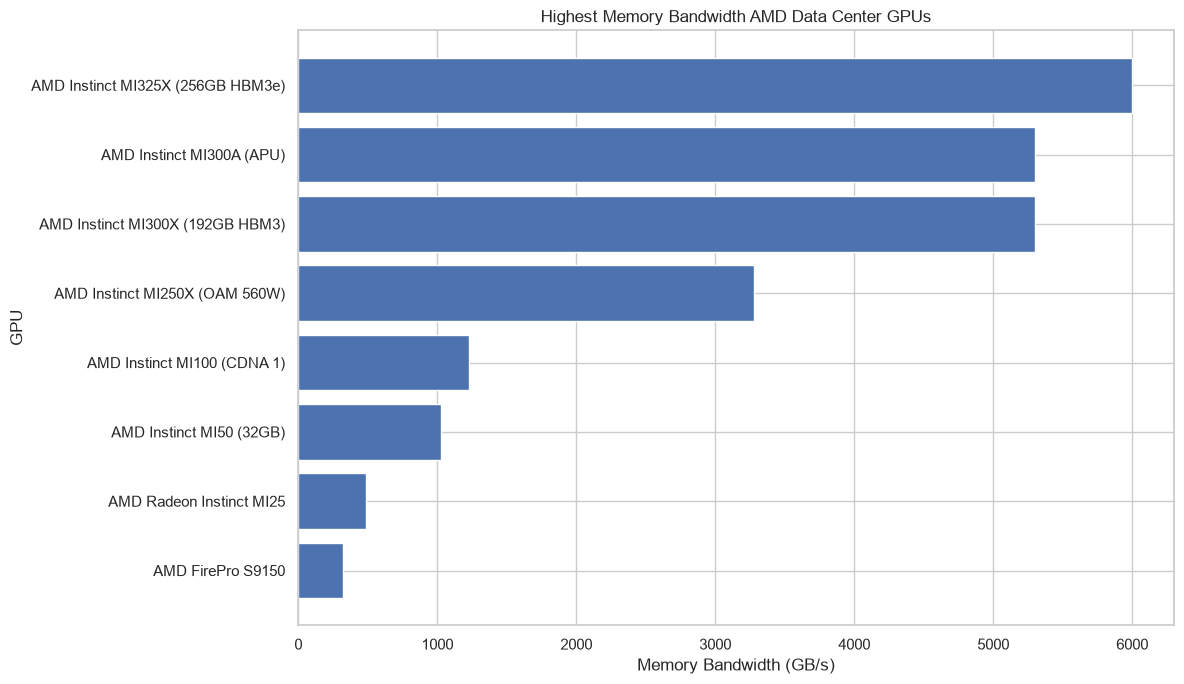

In [19]:
if df["memory_bandwidth_gbps"].notna().any():
    plot_df = df.dropna(subset=["memory_bandwidth_gbps"]).sort_values(
        "memory_bandwidth_gbps", ascending=False
    )

    cols = [c for c in [
        COLUMN_MAP["gpu_name"],
        COLUMN_MAP["architecture"],
        "memory_gb",
        "memory_bandwidth_gbps"
    ] if c]

    display(plot_df[cols].head(20))

    top = plot_df.head(15)
    labels = (
        top[COLUMN_MAP["gpu_name"]].astype(str)
        if COLUMN_MAP["gpu_name"]
        else top.index.astype(str)
    )

    plt.figure(figsize=(12, 7))
    plt.barh(labels[::-1], top["memory_bandwidth_gbps"].values[::-1])
    plt.title("Highest Memory Bandwidth AMD Data Center GPUs")
    plt.xlabel("Memory Bandwidth (GB/s)")
    plt.ylabel("GPU")
    plt.tight_layout()
    plt.show()
else:
    print("Memory bandwidth column not detected.")

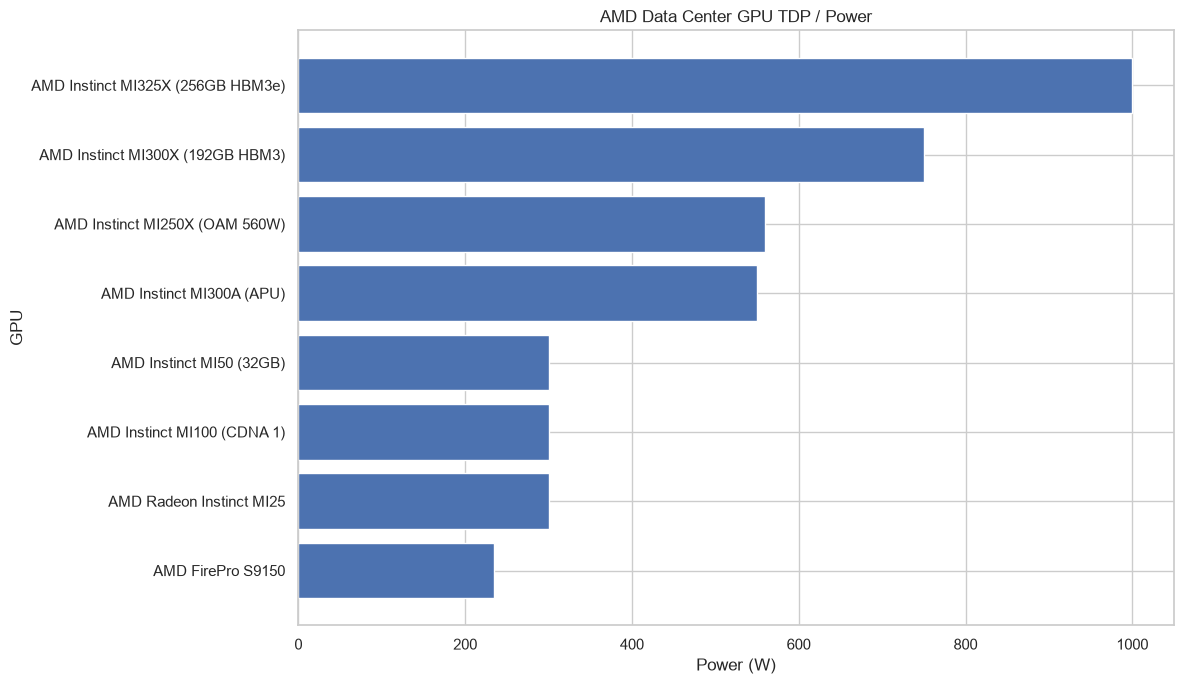

In [20]:
if df["tdp_w"].notna().any():
    plot_df = df.dropna(subset=["tdp_w"]).sort_values("tdp_w", ascending=False).head(20)

    labels = (
        plot_df[COLUMN_MAP["gpu_name"]].astype(str)
        if COLUMN_MAP["gpu_name"]
        else plot_df.index.astype(str)
    )

    plt.figure(figsize=(12, 7))
    plt.barh(labels[::-1], plot_df["tdp_w"].values[::-1])
    plt.title("AMD Data Center GPU TDP / Power")
    plt.xlabel("Power (W)")
    plt.ylabel("GPU")
    plt.tight_layout()
    plt.show()
else:
    print("TDP/power column not detected.")

,gpu_name,architecture,compute_performance,tdp_w,performance_per_watt
5,AMD Instinct MI300A (APU),CDNA 3.0 + Zen 4,122.60,550.0,0.222909
6,AMD Instinct MI300X (192GB HBM3),CDNA 3.0,163.40,750.0,0.217867
7,AMD Instinct MI325X (256GB HBM3e),CDNA 3.0 Refresh,163.40,1000.0,0.163400
4,AMD Instinct MI250X (OAM 560W),CDNA 2.0 (Dual-GCD),47.90,560.0,0.085536
3,AMD Instinct MI100 (CDNA 1),CDNA 1.0,23.07,300.0,0.076900
2,AMD Instinct MI50 (32GB),GCN 5.0 (Vega 20),13.25,300.0,0.044167
1,AMD Radeon Instinct MI25,GCN 5.0 (Vega),12.29,300.0,0.040967
0,AMD FirePro S9150,GCN 2.0,5.07,235.0,0.021574


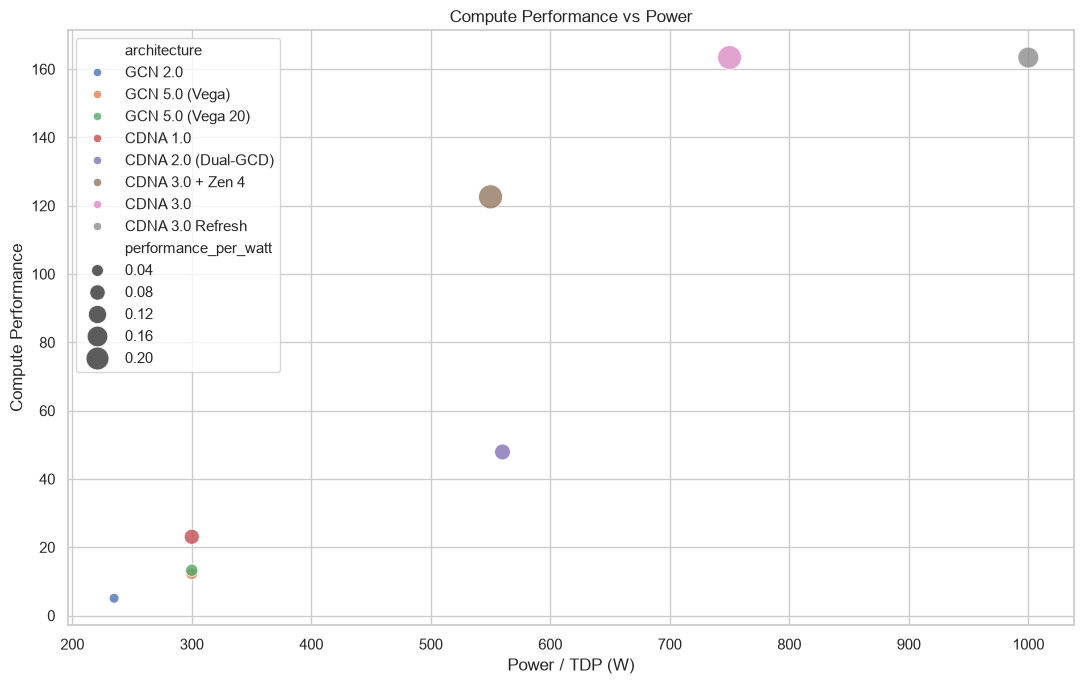

In [21]:
if df["compute_performance"].notna().any() and df["tdp_w"].notna().any():
    efficiency_df = df.dropna(
        subset=["compute_performance", "tdp_w"]
    ).copy()

    efficiency_df["performance_per_watt"] = (
        efficiency_df["compute_performance"] / efficiency_df["tdp_w"]
    )

    cols = [c for c in [
        COLUMN_MAP["gpu_name"],
        COLUMN_MAP["architecture"],
        "compute_performance",
        "tdp_w",
        "performance_per_watt"
    ] if c]

    display(
        efficiency_df.sort_values(
            "performance_per_watt",
            ascending=False
        )[cols].head(20)
    )

    plt.figure(figsize=(11, 7))
    sns.scatterplot(
        data=efficiency_df,
        x="tdp_w",
        y="compute_performance",
        hue=COLUMN_MAP["architecture"] if COLUMN_MAP["architecture"] else None,
        size="performance_per_watt",
        sizes=(50, 300),
        alpha=0.8
    )
    plt.title("Compute Performance vs Power")
    plt.xlabel("Power / TDP (W)")
    plt.ylabel("Compute Performance")
    plt.tight_layout()
    plt.show()
else:
    print("Performance-per-watt requires compute_performance and tdp_w.")

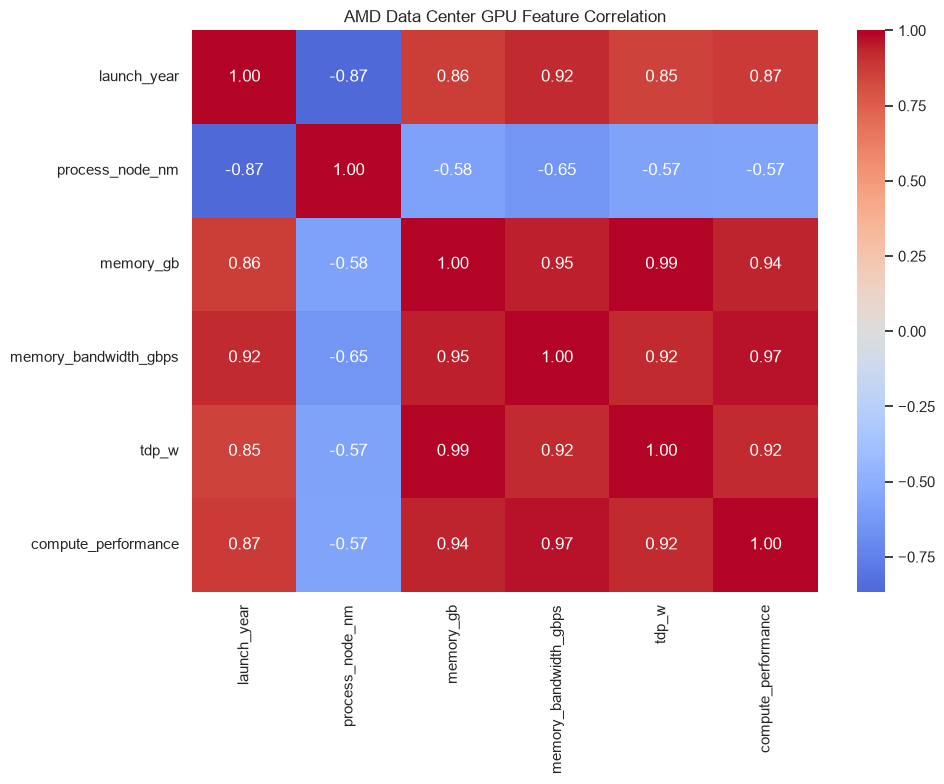

In [22]:
corr_cols = [
    c for c in [
        "launch_year",
        "process_node_nm",
        "memory_gb",
        "memory_bandwidth_gbps",
        "tdp_w",
        "compute_performance",
        "performance_per_watt"
    ]
    if c in df.columns and df[c].notna().sum() >= 2
]

if len(corr_cols) >= 2:
    corr = df[corr_cols].corr()

    plt.figure(figsize=(10, 8))
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
    plt.title("AMD Data Center GPU Feature Correlation")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough numeric fields for correlation.")

In [23]:
if COLUMN_MAP["architecture"]:
    agg_map = {}

    for col in [
        "memory_gb",
        "memory_bandwidth_gbps",
        "tdp_w",
        "compute_performance",
        "process_node_nm"
    ]:
        if col in df.columns and df[col].notna().any():
            agg_map[col] = ["count", "mean", "min", "max"]

    if agg_map:
        summary = df.groupby(COLUMN_MAP["architecture"]).agg(agg_map)
        display(summary.round(2))
    else:
        print("No numeric technical fields available.")
else:
    print("Architecture column not detected.")

memory_gb                      memory_bandwidth_gbps  \
                        count   mean    min    max                 count   
architecture                                                               
CDNA 1.0                    1   32.0   32.0   32.0                     1   
CDNA 2.0 (Dual-GCD)         1  128.0  128.0  128.0                     1   
CDNA 3.0                    1  192.0  192.0  192.0                     1   
CDNA 3.0 + Zen 4            1  128.0  128.0  128.0                     1   
CDNA 3.0 Refresh            1  256.0  256.0  256.0                     1   
GCN 2.0                     1   16.0   16.0   16.0                     1   
GCN 5.0 (Vega 20)           1   32.0   32.0   32.0                     1   
GCN 5.0 (Vega)              1   16.0   16.0   16.0                     1   

                                            tdp_w                          \
                       mean     min     max count    mean     min     max   
architecture                                                                
CDNA 1.0             1228.8  1228.8  1228.8     1   300.0   300.0   300.0   
CDNA 2.0 (Dual-GCD)  3276.8  3276.8  3276.8     1   560.0   560.0   560.0   
CDNA 3.0             5300.0  5300.0  5300.0     1   750.0   750.0   750.0   
CDNA 3.0 + Zen 4     5300.0  5300.0  5300.0     1   550.0   550.0   550.0   
CDNA 3.0 Refresh     6000.0  6000.0  6000.0     1  1000.0  1000.0  1000.0   
GCN 2.0               320.0   320.0   320.0     1   235.0   235.0   235.0   
GCN 5.0 (Vega 20)    1024.0  1024.0  1024.0     1   300.0   300.0   300.0   
GCN 5.0 (Vega)        484.0   484.0   484.0     1   300.0   300.0   300.0   

                    compute_performance                          \
                                  count    mean     min     max   
architecture                                                      
CDNA 1.0                              1   23.07   23.07   23.07   
CDNA 2.0 (Dual-GCD)                   1   47.90   47.90   47.90   
CDNA 3.0                              1  163.40  163.40  163.40   
CDNA 3.0 + Zen 4                      1  122.60  122.60  122.60   
CDNA 3.0 Refresh                      1  163.40  163.40  163.40   
GCN 2.0                               1    5.07    5.07    5.07   
GCN 5.0 (Vega 20)                     1   13.25   13.25   13.25   
GCN 5.0 (Vega)                        1   12.29   12.29   12.29   

                    process_node_nm                
                              count  mean min max  
architecture                                       
CDNA 1.0                          1   7.0   7   7  
CDNA 2.0 (Dual-GCD)               1   6.0   6   6  
CDNA 3.0                          1   5.0   5   5  
CDNA 3.0 + Zen 4                  1   5.0   5   5  
CDNA 3.0 Refresh                  1   5.0   5   5  
GCN 2.0                           1  28.0  28  28  
GCN 5.0 (Vega 20)                 1   7.0   7   7  
GCN 5.0 (Vega)                    1  14.0  14  14

In [24]:
dashboard_columns = [
    COLUMN_MAP["gpu_name"],
    COLUMN_MAP["series"],
    COLUMN_MAP["architecture"],
    "launch_year",
    "process_node_nm",
    "memory_gb",
    "memory_bandwidth_gbps",
    "tdp_w",
    "compute_performance",
]

dashboard_columns = [c for c in dashboard_columns if c]

display(df[dashboard_columns].head(30))

,gpu_name,series,architecture,launch_year,process_node_nm,memory_gb,memory_bandwidth_gbps,tdp_w,compute_performance
0,AMD FirePro S9150,FirePro Server,GCN 2.0,2014,28,16.0,320.0,235.0,5.07
1,AMD Radeon Instinct MI25,Instinct MI,GCN 5.0 (Vega),2017,14,16.0,484.0,300.0,12.29
2,AMD Instinct MI50 (32GB),Instinct MI,GCN 5.0 (Vega 20),2018,7,32.0,1024.0,300.0,13.25
3,AMD Instinct MI100 (CDNA 1),Instinct MI,CDNA 1.0,2020,7,32.0,1228.8,300.0,23.07
4,AMD Instinct MI250X (OAM 560W),Instinct MI,CDNA 2.0 (Dual-GCD),2021,6,128.0,3276.8,560.0,47.90
5,AMD Instinct MI300A (APU),Instinct MI,CDNA 3.0 + Zen 4,2023,5,128.0,5300.0,550.0,122.60
6,AMD Instinct MI300X (192GB HBM3),Instinct MI,CDNA 3.0,2023,5,192.0,5300.0,750.0,163.40
7,AMD Instinct MI325X (256GB HBM3e),Instinct MI,CDNA 3.0 Refresh,2024,5,256.0,6000.0,1000.0,163.40


In [25]:
insights = {}

if COLUMN_MAP["gpu_name"]:
    insights["total_gpu_records"] = int(len(df))
    insights["unique_gpu_models"] = int(df[COLUMN_MAP["gpu_name"]].nunique())

if df["launch_year"].notna().any():
    insights["earliest_launch_year"] = int(df["launch_year"].min())
    insights["latest_launch_year"] = int(df["launch_year"].max())

if df["memory_gb"].notna().any():
    idx = df["memory_gb"].idxmax()
    insights["highest_memory_gb"] = float(df.loc[idx, "memory_gb"])
    if COLUMN_MAP["gpu_name"]:
        insights["highest_memory_gpu"] = str(df.loc[idx, COLUMN_MAP["gpu_name"]])

if df["memory_bandwidth_gbps"].notna().any():
    idx = df["memory_bandwidth_gbps"].idxmax()
    insights["highest_bandwidth_gbps"] = float(df.loc[idx, "memory_bandwidth_gbps"])
    if COLUMN_MAP["gpu_name"]:
        insights["highest_bandwidth_gpu"] = str(df.loc[idx, COLUMN_MAP["gpu_name"]])

if df["tdp_w"].notna().any():
    idx = df["tdp_w"].idxmax()
    insights["highest_tdp_w"] = float(df.loc[idx, "tdp_w"])
    if COLUMN_MAP["gpu_name"]:
        insights["highest_tdp_gpu"] = str(df.loc[idx, COLUMN_MAP["gpu_name"]])

display(pd.Series(insights, name="value").to_frame())

,value
total_gpu_records,8
unique_gpu_models,8
earliest_launch_year,2014
latest_launch_year,2024
highest_memory_gb,256.0
highest_memory_gpu,AMD Instinct MI325X (256GB HBM3e)
highest_bandwidth_gbps,6000.0
highest_bandwidth_gpu,AMD Instinct MI325X (256GB HBM3e)
highest_tdp_w,1000.0
highest_tdp_gpu,AMD Instinct MI325X (256GB HBM3e)


In [26]:
output_dir = Path("../data")
if not output_dir.exists():
    output_dir = Path("data")

output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / "amd_datacenter_gpus_clean.csv"

df.to_csv(output_path, index=False)

print(f"Saved cleaned dataset to: {output_path.resolve()}")

Saved cleaned dataset to: E:\DataCenterIQ\data\amd_datacenter_gpus_clean.csv
